In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import subprocess
import re
from nltk.corpus import wordnet

import warnings
warnings.filterwarnings("ignore")

## 1. Load Dataset

In [2]:
path = r"C:\Users\RTX\Desktop\ticket_routing\processed\clean_dataset.jsonl"

tickets  = pd.read_json(path, lines=True)


In [3]:
tickets

,text,label,length
0,I noticed a charge on my account that I wasn't...,billing,96
1,Can you explain why there's an extra fee on my...,billing,97
2,"I looked at my payment history, and it seems l...",billing,107
3,"Hey, I got my invoice and it's way higher than...",billing,80
4,I think I'm being charged for two subscription...,billing,95
...,...,...,...
11688,Why does my API key keep getting invalidated? ...,api,72
11689,Can you explain how to authenticate using Basi...,api,83
11690,I’m trying to pull data from the specified end...,api,95
11691,"I’ve read the documentation, but I’m still con...",api,108


## 2. Explore Data (EDA)

In [4]:
tickets.shape

(11693, 3)

In [5]:
tickets.head()

,text,label,length
0,I noticed a charge on my account that I wasn't...,billing,96
1,Can you explain why there's an extra fee on my...,billing,97
2,"I looked at my payment history, and it seems l...",billing,107
3,"Hey, I got my invoice and it's way higher than...",billing,80
4,I think I'm being charged for two subscription...,billing,95


In [6]:
tickets.tail()

,text,label,length
11688,Why does my API key keep getting invalidated? ...,api,72
11689,Can you explain how to authenticate using Basi...,api,83
11690,I’m trying to pull data from the specified end...,api,95
11691,"I’ve read the documentation, but I’m still con...",api,108
11692,Why is my integration with the third-party ser...,api,105


In [7]:
tickets.dtypes

text        str
label       str
length    int64
dtype: object

In [8]:
tickets.info()

<class 'pandas.DataFrame'>
RangeIndex: 11693 entries, 0 to 11692
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    11693 non-null  str  
 1   label   11693 non-null  str  
 2   length  11693 non-null  int64
dtypes: int64(1), str(2)
memory usage: 1.2 MB


In [9]:
null = tickets.isnull().sum()
null[null > 0]

Series([], dtype: int64)

In [10]:
tickets.nunique().sort_values(ascending=False)

text      11693
length       91
label         6
dtype: int64

In [11]:
tickets.describe()

,length
count,11693.000000
mean,70.834174
std,12.412456
min,32.000000
25%,62.000000
50%,70.000000
75%,79.000000
max,141.000000


In [12]:
for col in tickets.columns:
    print(tickets[col].value_counts())

text
I noticed a charge on my account that I wasn't expecting. Can you help me figure out what it is?                1
Can you explain why there's an extra fee on my latest bill? It's not something I'm familiar with.               1
I looked at my payment history, and it seems like I was billed for a service I didn't use. What's going on?     1
Hey, I got my invoice and it's way higher than usual. Can you check that for me?                                1
I think I'm being charged for two subscriptions when I only signed up for one. Can you clarify?                 1
                                                                                                               ..
Why does my API key keep getting invalidated? This is super frustrating!                                        1
Can you explain how to authenticate using Basic Auth with your API? I'm a bit lost.                             1
I’m trying to pull data from the specified endpoint, but it keeps timing out. What 

In [13]:
tickets.duplicated().sum()

np.int64(0)

In [14]:
import re
import string

text = tickets["text"].fillna("").astype(str)

print(f"\n{'='*20} TEXT QUALITY CHECK {'='*20}")

# Basic Text Checks
print("Empty:", text.str.strip().eq("").sum())
print("Uppercase:", text.str.contains(r"[A-Z]").sum())
print("Lowercase:", text.str.contains(r"[a-z]").sum())

# Numbers & Characters
print("Numbers:", text.str.contains(r"\d").sum())
print("Digits Only Tokens:",
      text.str.contains(r"\b\d+\b").sum())
print("Special Characters:",
      text.str.contains(r"[^a-zA-Z0-9\s]").sum())
print("Punctuation:",
      text.str.contains(rf"[{re.escape(string.punctuation)}]").sum())

# Apostrophes & Contractions
print("Apostrophes:",
      text.str.contains(r"['’]").sum())

print("Possessives:",
      text.str.contains(r"\b[a-zA-Z]+['’]s\b").sum())

print("Contractions:",
      text.str.contains(
          r"\b[a-zA-Z]+['’](t|re|ve|ll|d|m)\b"
      ).sum())

# Hyphens
print("Hyphenated Words:",
      text.str.contains(r"\b\w+-\w+\b").sum())

# Whitespace
print("Extra Spaces:",
      text.str.contains(r" {2,}").sum())

print("Tabs:",
      text.str.contains(r"\t").sum())

print("Leading/Trailing Spaces:",
      text.apply(lambda x: x != x.strip()).sum())

print("Line Breaks:",
      text.str.count(r"\n").sum())

# URLs / Emails / HTML
print("URLs:",
      text.str.contains(r"https?://\S+|www\.\S+").sum())

print("Emails:",
      text.str.contains(
          r"\b[\w.-]+@[\w.-]+\.\w+\b"
      ).sum())

print("HTML Tags:",
      text.str.contains(r"<[^>]+>").sum())

# Text Statistics
words = text.str.split()
word_counts = words.str.len()

print("\n--- Text Statistics ---")

print("Min Words:", word_counts.min())
print("Max Words:", word_counts.max())
print("Average Words:", round(word_counts.mean(), 2))

print("Min Characters:", text.str.len().min())
print("Max Characters:", text.str.len().max())
print("Average Characters:", round(text.str.len().mean(), 2))

# Dataset Statistics
print("\n--- Dataset Statistics ---")

print("Total Tickets:", len(tickets))
print("Unique Labels:", tickets["label"].nunique())
print("Duplicate Rows:", tickets.duplicated().sum())
print("Duplicate Text:", tickets["text"].duplicated().sum())


==================== TEXT QUALITY CHECK ====================
Empty: 0
Uppercase: 11693
Lowercase: 11693
Numbers: 185
Digits Only Tokens: 171
Special Characters: 11693
Punctuation: 11693
Apostrophes: 6723
Possessives: 1817
Contractions: 5536
Hyphenated Words: 211
Extra Spaces: 1
Tabs: 0
Leading/Trailing Spaces: 0
Line Breaks: 0
URLs: 0
Emails: 0
HTML Tags: 0

--- Text Statistics ---
Min Words: 5
Max Words: 26
Average Words: 13.07
Min Characters: 32
Max Characters: 141
Average Characters: 70.83

--- Dataset Statistics ---
Total Tickets: 11693
Unique Labels: 6
Duplicate Rows: 0
Duplicate Text: 0


## 3. EDA

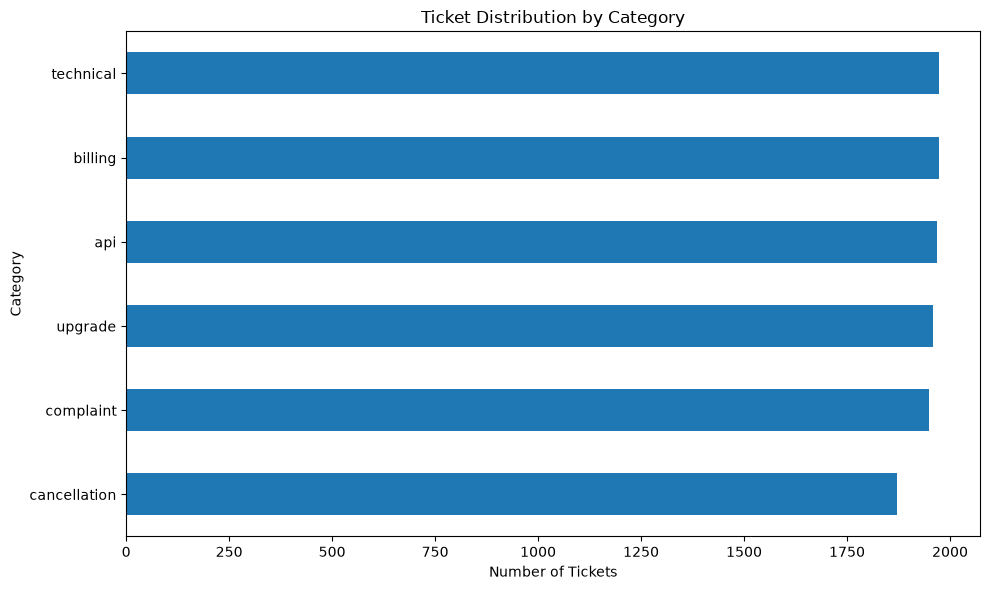

In [15]:
label_counts = tickets["label"].value_counts()

plt.figure(figsize=(10, 6))
label_counts.sort_values().plot(kind="barh")

plt.title("Ticket Distribution by Category")
plt.xlabel("Number of Tickets")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

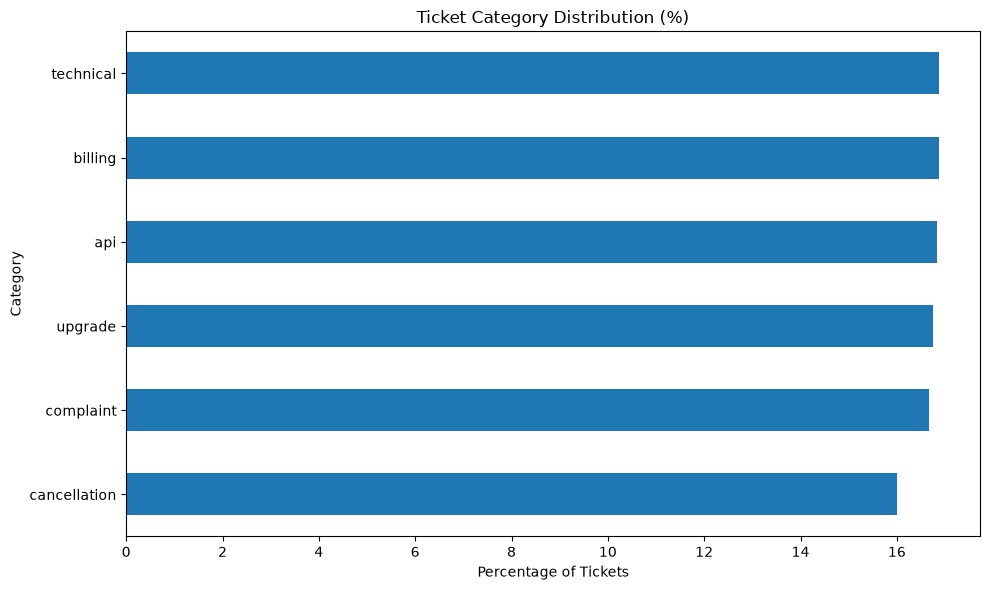

In [16]:
label_percent = (
    tickets["label"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
label_percent.sort_values().plot(kind="barh")

plt.title("Ticket Category Distribution (%)")
plt.xlabel("Percentage of Tickets")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

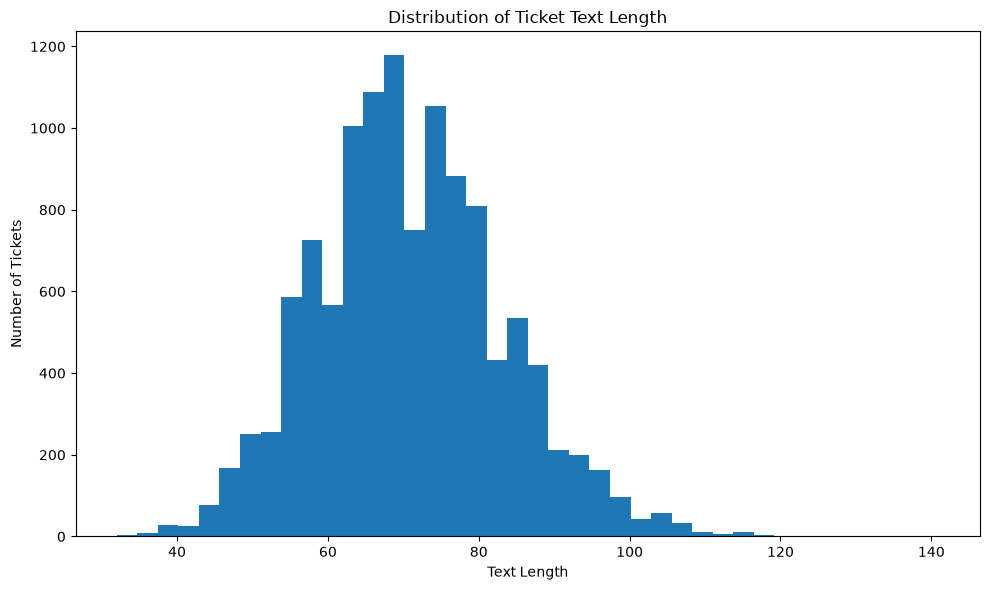

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(tickets["length"], bins=40)

plt.title("Distribution of Ticket Text Length")
plt.xlabel("Text Length")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

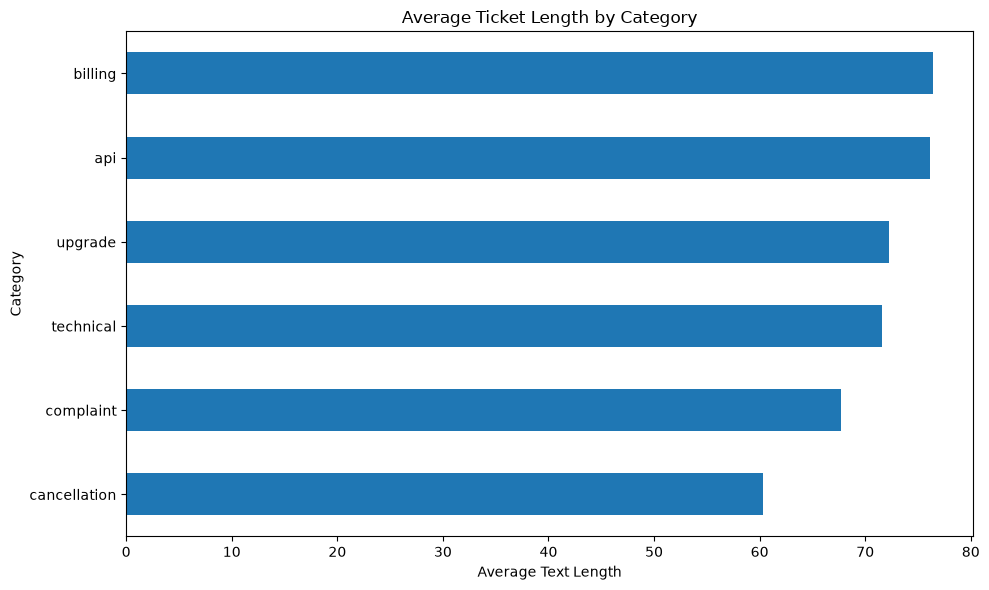

In [18]:
avg_length = (
    tickets.groupby("label")["length"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 6))
avg_length.plot(kind="barh")

plt.title("Average Ticket Length by Category")
plt.xlabel("Average Text Length")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## 4.  Text Preprocessing

In [19]:
import re

def clean_text(text):
    text = text.lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Expand common contractions
    contractions = {
        "don't": "do not",
        "doesn't": "does not",
        "didn't": "did not",
        "can't": "cannot",
        "couldn't": "could not",
        "won't": "will not",
        "wouldn't": "would not",
        "isn't": "is not",
        "aren't": "are not",
        "wasn't": "was not",
        "weren't": "were not",
        "haven't": "have not",
        "hasn't": "has not",
        "hadn't": "had not",
        "shouldn't": "should not",
        "mustn't": "must not",
        "i'm": "i am",
        "i'll": "i will",
        "i've": "i have",
        "i'd": "i would",
        "you're": "you are",
        "you'll": "you will",
        "you've": "you have",
        "you'd": "you would",
        "we're": "we are",
        "we'll": "we will",
        "we've": "we have",
        "we'd": "we would",
        "they're": "they are",
        "they'll": "they will",
        "they've": "they have",
        "they'd": "they would"
    }

    for contraction, expansion in contractions.items():
        text = re.sub(
            rf"\b{re.escape(contraction)}\b",
            expansion,
            text
        )

    # Remove punctuation / special characters
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [20]:
tickets["clean_text"] = tickets["text"].apply(clean_text)

In [21]:
tickets[["text", "clean_text"]].sample(10, random_state=42)     # مقارنة 

,text,clean_text
8727,I feel like I've been wasting my time; this is...,i feel like i have been wasting my time this i...
4884,"I’d like to close my account, as I’m not findi...",i d like to close my account as i m not findin...
5023,I want to discontinue my account. It’s just no...,i want to discontinue my account it s just not...
468,My invoice is missing some information that I ...,my invoice is missing some information that i ...
9149,This has been the most disappointing experienc...,this has been the most disappointing experienc...
7334,How do I add more users to my current plan? Is...,how do i add more users to my current plan is ...
1864,Why was I charged in advance for my subscripti...,why was i charged in advance for my subscripti...
3208,Why does the search function return no results...,why does the search function return no results...
6158,Is it easy to downgrade my subscription if I f...,is it easy to downgrade my subscription if i f...
3693,This is ridiculous! The checkout process keeps...,this is ridiculous the checkout process keeps ...


## 5.Create Model

In [22]:
from sklearn.model_selection import train_test_split  
from sklearn.model_selection import cross_val_score    
from sklearn.neighbors import KNeighborsClassifier       
from sklearn.tree import DecisionTreeClassifier         
from sklearn.naive_bayes import GaussianNB              
from sklearn.svm import SVC                             
from sklearn.ensemble import RandomForestClassifier      
from sklearn.ensemble import GradientBoostingClassifier 
from sklearn.linear_model import LogisticRegression     

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix        
from sklearn.metrics import classification_report     
from sklearn.metrics import accuracy_score           
from sklearn.metrics import roc_auc_score             
from sklearn.metrics import roc_curve               
from sklearn.metrics import f1_score                   


from sklearn.model_selection import train_test_split

X = tickets["clean_text"]
y = tickets["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 9354
Testing samples: 2339


In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 3),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("X_train shape:", X_train_tfidf.shape)
print("X_test shape:", X_test_tfidf.shape)



X_train shape: (9354, 10000)
X_test shape: (2339, 10000)


In [24]:
from sklearn.metrics import f1_score

f1_scores = []

def all(model):
    model.fit(X_train_tfidf, y_train)
    
    pred = model.predict(X_test_tfidf)
    
    f1 = f1_score(y_test, pred, average="macro")
    
    print("F1 Score =", f1)
    
    f1_scores.append(f1)

In [25]:
from sklearn.linear_model import LogisticRegression

model1 = LogisticRegression(max_iter=2000)
all(model1)

F1 Score = 0.9901977944903909


In [26]:
from sklearn.svm import LinearSVC

model2 = LinearSVC()
all(model2)

F1 Score = 0.9948731880512279


In [27]:
from sklearn.linear_model import RidgeClassifier

model3 = RidgeClassifier()
all(model3)

F1 Score = 0.9957197740678208


In [28]:
from sklearn.linear_model import SGDClassifier

model4 = SGDClassifier(
    loss="hinge",
    max_iter=2000,
    random_state=42
)
all(model4)

F1 Score = 0.9944341713975312


In [29]:
model5 = SGDClassifier(
    loss="log_loss",
    max_iter=2000,
    random_state=42
)
all(model5)

F1 Score = 0.9888995277520749


In [30]:
model6 = SGDClassifier(
    loss="modified_huber",
    max_iter=2000,
    random_state=42
)
all(model6)

F1 Score = 0.9940239290661338


In [31]:
from sklearn.naive_bayes import MultinomialNB

model7 = MultinomialNB()
all(model7)

F1 Score = 0.9859475837453308


In [32]:
from sklearn.naive_bayes import ComplementNB

model8 = ComplementNB()
all(model8)

F1 Score = 0.98804920559966


In [33]:
from sklearn.naive_bayes import BernoulliNB

model9 = BernoulliNB()
all(model9)

F1 Score = 0.9876281527215832


In [34]:
model10 = KNeighborsClassifier(n_neighbors=10)
all(model10)

F1 Score = 0.9467609179105886


In [35]:
from sklearn.tree import DecisionTreeClassifier

model11 = DecisionTreeClassifier(
    random_state=42
)
all(model11)

F1 Score = 0.9123085072344411


In [36]:
from sklearn.ensemble import RandomForestClassifier

model12 = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
all(model12)

F1 Score = 0.9752281074376699


In [37]:
from sklearn.ensemble import ExtraTreesClassifier

model13 = ExtraTreesClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
all(model13)

F1 Score = 0.983351843689955


In [38]:
# AdaBoost
from sklearn.ensemble import AdaBoostClassifier

model14 = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)
all(model14)

F1 Score = 0.7555273071017553


In [39]:
from sklearn.linear_model import RidgeClassifier
from sklearn.metrics import f1_score

model = RidgeClassifier()

model.fit(X_train_tfidf, y_train)

pred = model.predict(X_test_tfidf)

f1 = f1_score(y_test, pred, average="macro")

print("F1 Score =", f1)

f1_scores.append(f1)

F1 Score = 0.9957197740678208


In [40]:
from sklearn.metrics import classification_report

print("Classification Report:\n")
print(classification_report(y_test, pred))

Classification Report:

              precision    recall  f1-score   support

         api       1.00      0.99      1.00       394
     billing       0.99      0.99      0.99       394
cancellation       0.99      0.99      0.99       374
   complaint       1.00      1.00      1.00       390
   technical       0.99      0.99      0.99       395
     upgrade       0.99      1.00      1.00       392

    accuracy                           1.00      2339
   macro avg       1.00      1.00      1.00      2339
weighted avg       1.00      1.00      1.00      2339



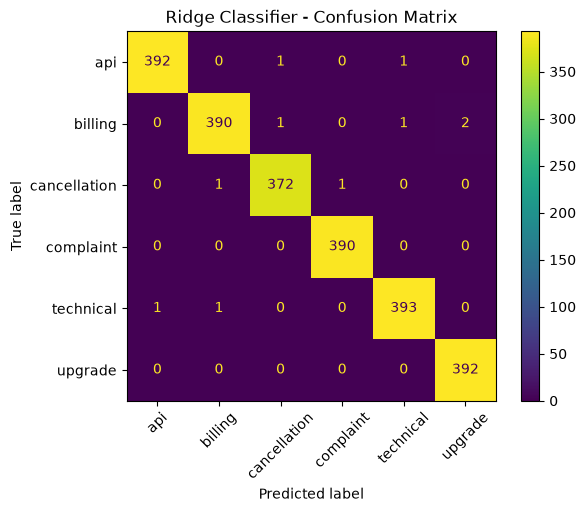

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(xticks_rotation=45)
plt.title("Ridge Classifier - Confusion Matrix")
plt.show()

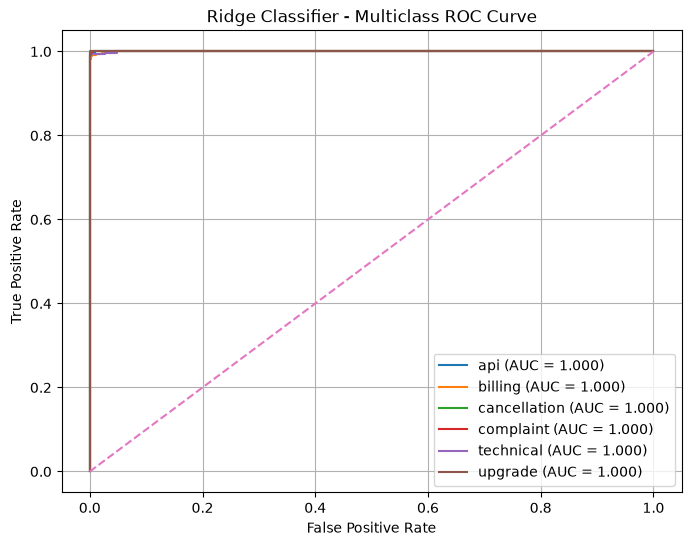

In [42]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

classes = model.classes_

y_test_bin = label_binarize(y_test, classes=classes)

y_score = model.decision_function(X_test_tfidf)

plt.figure(figsize=(8, 6))

for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_score[:, i]
    )
    
    roc_auc = auc(fpr, tpr)
    
    plt.plot(
        fpr,
        tpr,
        label=f"{cls} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Ridge Classifier - Multiclass ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [44]:
import os
import pickle

PROJECT_DIR = r"C:\Users\RTX\Desktop\TicketRoutingSystem"

# Create folders
os.makedirs(os.path.join(PROJECT_DIR, "data"), exist_ok=True)
os.makedirs(os.path.join(PROJECT_DIR, "model"), exist_ok=True)

# Save Dataset
tickets.to_csv(
    os.path.join(PROJECT_DIR, "data", "tickets.csv"),
    index=False
)

# Save Model
with open(
    os.path.join(PROJECT_DIR, "model", "ridge_classifier.pkl"),
    "wb"
) as file:
    pickle.dump(model, file)

# Save TF-IDF Vectorizer
with open(
    os.path.join(PROJECT_DIR, "model", "tfidf_vectorizer.pkl"),
    "wb"
) as file:
    pickle.dump(tfidf, file)

print("Dataset, Model and TF-IDF saved successfully.")

Dataset, Model and TF-IDF saved successfully.
